**TASKS FOR AI**
Prompt 1: 

Context: I have a dataframe with product information for a store.

Task: Determine the product turnover rate for each product in the table using a SQL query.

Table Schema: The table has a column named product_id that holds the different product types. It has another column called sales_last_30_days. Use that column to find the sales frequency for each product. 
Additional prompt: I have another column titled last_restock_date. Can I use this column to get a better turnover rate? 

Second task: Using the results from the first task, suggest code to create a table to visualize the different turnover rates. 

Third task: Find the five products with the slowest turnover rates using the results from the first task.

Fourth task: Suggest a way to visualize the results from the Third task

Fifth task: Predict products that are likely to run out. 

Table Schema for the fifth task: The table has a column called stock_level. Using a SQL query that considers each product’s turnover rate, predict which products are likely to run out. 


**Code from the first AI SQL query for my first task**
SELECT 
	product_id, 
	sales_last_30_days, -- Daily sales frequency / turnover rate 
ROUND(sales_last_30_days / 30.0, 2) AS daily_turnover_rate 
FROM product_inventory;

**Code from corrected AI SQL query**
SELECT 
	product_id, 
	sales_last_30_days, 
	last_restock_date, 
-- Days since restock (minimum 1 day to prevent division by zero) 	GREATEST(DATEDIFF(CURRENT_DATE, last_restock_date), 1) AS days_since_restock, 

-- True daily sales rate over active shelf days (capped at 30 days) 
ROUND( sales_last_30_days * 1.0 / LEAST(GREATEST(DATEDIFF(CURRENT_DATE, last_restock_date), 1), 30), 2 ) AS adjusted_daily_turnover 
FROM product_inventory; 

**SQL code for third task**

SELECT 
    product_id,
    sales_last_30_days,
    last_restock_date,
    -- Days active on shelf (capped at 30 days)
    LEAST(GREATEST(DATEDIFF(CURRENT_DATE, last_restock_date), 1), 30) AS active_days,
    -- Adjusted daily turnover rate
    ROUND(
        sales_last_30_days * 1.0 / LEAST(GREATEST(DATEDIFF(CURRENT_DATE, last_restock_date), 1), 30), 
        2
    ) AS adjusted_daily_turnover
FROM 
    product_inventory
ORDER BY 
    adjusted_daily_turnover ASC
LIMIT 5;

**Code for fifth task**
WITH product_metrics AS (
    SELECT 
        product_id,
        stock_level,
        sales_last_30_days,
        last_restock_date,
        -- Calculate adjusted daily turnover rate (avoiding division by zero)
        GREATEST(
            sales_last_30_days * 1.0 / LEAST(GREATEST(DATEDIFF(CURRENT_DATE, last_restock_date), 1), 30), 
            0.01
        ) AS daily_turnover_rate
    FROM 
        product_inventory
)
SELECT 
    product_id,
    stock_level,
    ROUND(daily_turnover_rate, 2) AS daily_turnover_rate,
    -- Calculate days of stock remaining until stockout
    ROUND(stock_level / daily_turnover_rate, 1) AS days_until_stockout,
    -- Flag urgency level based on estimated days remaining
    CASE 
        WHEN (stock_level / daily_turnover_rate) <= 3 THEN 'CRITICAL (Run out in ≤ 3 days)'
        WHEN (stock_level / daily_turnover_rate) <= 7 THEN 'WARNING (Run out in ≤ 7 days)'
        ELSE 'OK'
    END AS stockout_risk_status
FROM 
    product_metrics
WHERE 
    (stock_level / daily_turnover_rate) <= 7
ORDER BY 
    days_until_stockout ASC;



Product Turnover Summary:
product_id  sales_last_30_days  days_since_restock  adjusted_daily_turnover
  PROD-002                  15                  10                      1.5
  PROD-004                  45                  30                      1.5
  PROD-001                 120                  30                      4.0
  PROD-005                  90                   5                     18.0
  PROD-003                 300                  15                     20.0


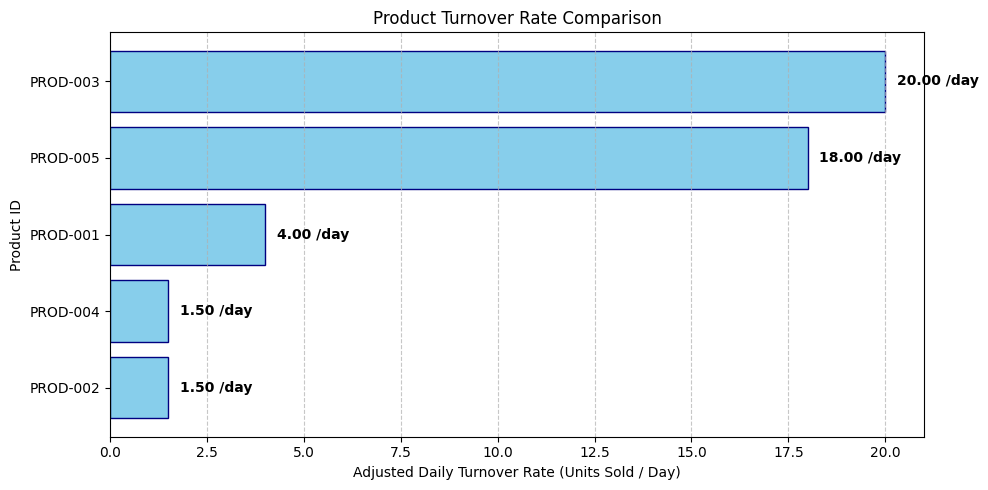

In [11]:
#Code for second task
import matplotlib.pyplot as plt
import pandas as pd

# 1. Load your query results into a pandas DataFrame
# Replace this mock dictionary with your SQL query connection (e.g., pd.read_sql(query, conn))
data = {
    'product_id': ['PROD-001', 'PROD-002', 'PROD-003', 'PROD-004', 'PROD-005'],
    'sales_last_30_days': [120, 15, 300, 45, 90],
    'days_since_restock': [30, 10, 15, 30, 5],
    'adjusted_daily_turnover': [4.00, 1.50, 20.00, 1.50, 18.00]
}

df = pd.DataFrame(data)

# Sort by turnover rate for better visualization
df = df.sort_values(by='adjusted_daily_turnover', ascending=True)

# 2. Display the sorted DataFrame table
print("Product Turnover Summary:")
print(df.to_string(index=False))

# 3. Create a horizontal bar plot for visual comparison
plt.figure(figsize=(10, 5))
bars = plt.barh(df['product_id'], df['adjusted_daily_turnover'], color='skyblue', edgecolor='navy')

# Add exact turnover values at the end of each bar
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.3, bar.get_y() + bar.get_height()/2, f'{width:.2f} /day', 
             va='center', fontsize=10, fontweight='bold')

plt.xlabel('Adjusted Daily Turnover Rate (Units Sold / Day)')
plt.ylabel('Product ID')
plt.title('Product Turnover Rate Comparison')
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

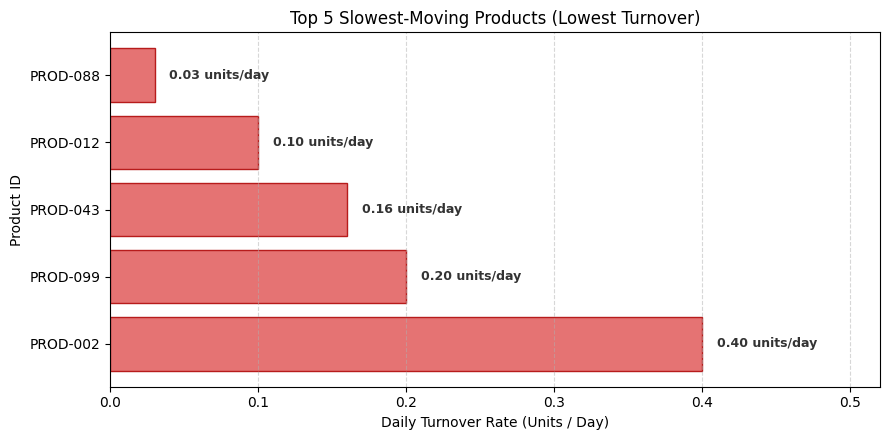

In [12]:
#Code for fourth task
# 1. Load the top 5 slowest products from your query results
data = {
    'product_id': ['PROD-088', 'PROD-012', 'PROD-043', 'PROD-099', 'PROD-002'],
    'sales_last_30_days': [1, 3, 4, 6, 8],
    'active_days': [30, 30, 25, 30, 20],
    'adjusted_daily_turnover': [0.03, 0.10, 0.16, 0.20, 0.40]
}

df = pd.DataFrame(data)

# Sort descending so the absolute lowest turnover rate is at the top of the horizontal chart
df = df.sort_values(by='adjusted_daily_turnover', ascending=False)

# 2. Plot the horizontal bar chart
plt.figure(figsize=(9, 4.5))
bars = plt.barh(df['product_id'], df['adjusted_daily_turnover'], color='#E57373', edgecolor='#B71C1C')

# Add data value labels on each bar
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.01, bar.get_y() + bar.get_height()/2, f'{width:.2f} units/day', 
             va='center', fontsize=9, fontweight='bold', color='#333333')

plt.xlabel('Daily Turnover Rate (Units / Day)')
plt.ylabel('Product ID')
plt.title('Top 5 Slowest-Moving Products (Lowest Turnover)')
plt.xlim(0, max(df['adjusted_daily_turnover']) * 1.3)  # Leave room for text labels
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [10]:
import pandas as pd

def analyze_user_engagement(logs_df):
    # Clean data: handle negative durations from bad tracking/timezone mismatches
    df = logs_df.copy()
    df['duration'] = df['duration'].clip(lower=0)
    
    # First aggregate logs to the session level
    session_df = df.groupby('session_id').agg(
        total_page_views=('page_views', 'sum'),
        total_duration=('duration', 'sum')
    )
    
    # Calculate overall engagement metrics correctly
    metrics = {
        # Proportion of sessions with exactly 1 page view
        'bounce_rate': (session_df['total_page_views'] == 1).mean(),
        
        # Average total session time across all sessions
        'avg_session_time': session_df['total_duration'].mean(),
        
        # Average total page views per session across all sessions
        'pages_per_session': session_df['total_page_views'].mean()
    }
    
    # Aggregate device-level metrics correctly
    device_metrics = df.groupby('device_type').agg(
        total_sessions=('session_id', 'nunique'),  # Count distinct sessions
        avg_duration=('duration', 'mean'),
        total_page_views=('page_views', 'sum')
    )
    
    return metrics, device_metrics

**SECOND SCENARIO**
Prompt: I have code to calculate user engagement metrics on a website, using a database of logs. I am observing errors where the results are impossible, like bounce rates that are over 100% or negative session times. Here is the code I’m using. What is wrong? [code text sent to AI here]

Result:
import pandas as pd

def analyze_user_engagement(logs_df):
    # Clean data: handle negative durations from bad tracking/timezone mismatches
    df = logs_df.copy()
    df['duration'] = df['duration'].clip(lower=0)
    
    # First aggregate logs to the session level
    session_df = df.groupby('session_id').agg(
        total_page_views=('page_views', 'sum'),
        total_duration=('duration', 'sum')
    )
    
    # Calculate overall engagement metrics correctly
    metrics = {
        # Proportion of sessions with exactly 1 page view
        'bounce_rate': (session_df['total_page_views'] == 1).mean(),
        
        # Average total session time across all sessions
        'avg_session_time': session_df['total_duration'].mean(),
        
        # Average total page views per session across all sessions
        'pages_per_session': session_df['total_page_views'].mean()
    }
    
    # Aggregate device-level metrics correctly
    device_metrics = df.groupby('device_type').agg(
        total_sessions=('session_id', 'nunique'),  # Count distinct sessions
        avg_duration=('duration', 'mean'),
        total_page_views=('page_views', 'sum')
    )
    
    return metrics, device_metrics


**Third Scenario**

Prompt: 

Task: Generate a SQL query to identify active, high-spending users. An active user is a user who has logged in in the last 30 days. High-spending users are defined as users who are in the top 20% by spending. Once those customers are identified, find what preferences they use most often.

Context: The database has three tables: user_activity, transactions, and user_preferences.
  From the user_activity table, there are two columns, user_id, last_login_date. Use the last_login_date column to identify active customers. Then, join the user_activity table to the transactions table on user_id. The transactions table has a column named amount. Use this column to identify the top 20% spending customers. Once the top active customers are identified, join the user_preferences table on the user_id column. This table has three other columns: communication_preference, interface_theme, and notification_settings. Use this table to identify trends in the top customers. 

Result: 

WITH active_user_spending AS (
    SELECT 
        ua.user_id,
        SUM(t.amount) AS total_spent,
        -- Divide users into 5 equal spending buckets (Bucket 1 = top 20%)
        NTILE(5) OVER (ORDER BY SUM(t.amount) DESC) AS spending_bucket
    FROM 
        user_activity ua
    JOIN 
        transactions t ON ua.user_id = t.user_id
    WHERE 
        -- Filter for users active in the last 30 days
        ua.last_login_date >= CURRENT_DATE - INTERVAL '30 days'
    GROUP BY 
        ua.user_id
),
top_20_percent_users AS (
    SELECT 
        user_id,
        total_spent
    FROM 
        active_user_spending
    WHERE 
        spending_bucket = 1
)
-- Aggregate preferences for the top 20% active spenders
SELECT 
    up.communication_preference,
    up.interface_theme,
    up.notification_settings,
    COUNT(t20.user_id) AS user_count,
    ROUND(
        COUNT(t20.user_id) * 100.0 / SUM(COUNT(t20.user_id)) OVER (), 2
    ) AS percentage_of_top_users
FROM 
    top_20_percent_users t20
JOIN 
    user_preferences up ON t20.user_id = up.user_id
GROUP BY 
    up.communication_preference,
    up.interface_theme,
    up.notification_settings
ORDER BY 
    user_count DESC;